# Stage 0: Gaussian testbed

Plan: `docs/experiment_plan_enron_gptneo125m.md`, section 4, row 0 (draft App. I). CPU only, runs locally.

**Gate:** Claim 1 holds numerically. If it does not, the C3 story needs rethinking before any LLM run.

| Block | Question | Code | Full-budget time (laptop CPU) |
|---|---|---|---|
| 0 | Self-tests: closed forms, Prop. 5(a), AUROC envelope, certificate formulas | `ui_toy.selftest`, `common/certificates.py` | ~1 min |
| 1 | **Claim 1**: J(T̂) < Adv*_B(θ) for m ≥ 2; feasible Λ_m | `stage0_checks.run_q1` | ~1.5 min |
| 2 | **Prop. 6**: Var(S_m\|b) = v_B + v_W/m, eq. (3), ceiling; Step-F pilot at Enron scale | `stage0_checks.run_q2` | ~5 min (estimate) |
| 3 | **Cor. 2**: τ = own + typicality, sandwich, per-user TPR(m) → 1{τ_u > t_γ} | `stage0_checks.run_q3` | measured in the quick run, see block 3 |
| 4 | Context from `ui_toy`: m sweep (E1), heterogeneous k (E2c), DKW coverage (E6) | `ui_toy.exp_*` | E1 ~3.5 min, E2c ~2 min, E6 ~3 min |
| 5 | Gate verdict | | |

Results are cached as JSON in `results/` (git-ignored). A block recomputes only if its file is missing or its name is in `FORCE`.
`QUICK = True` uses tiny budgets and writes to `_quick/`, so the full results are never overwritten. Use it as a smoke test only.

In [1]:
import os, sys, json, time, runpy
QUICK = False          # True: smoke-test budgets, outputs in Stage0/_quick/
FORCE = set()          # e.g. {"stage0_q2"} to recompute a block

HERE = os.path.abspath("")                      # this notebook lives in Stage0/
ROOT = os.path.dirname(HERE)
os.environ["UIA_OUT_DIR"] = os.path.join(HERE, "_quick") if QUICK else HERE   # read by ui_toy at import
for p in (HERE, ROOT):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import ui_toy as T
import stage0_checks as S
from common import certificates as cert

BUD = S.BUDGETS["quick" if QUICK else "full"]
os.makedirs(T.RES, exist_ok=True); os.makedirs(T.FIG, exist_ok=True)
pd.set_option("display.precision", 3)

def cached(name, fn):
    path = os.path.join(T.RES, name + ".json")
    if name not in FORCE and os.path.exists(path):
        print(f"[{name}] loaded from {path}")
        return T.load(name)
    t0 = time.time()
    out = fn()
    T.save(name, out)
    print(f"[{name}] computed in {time.time() - t0:.0f}s -> {path}")
    return out

print("results:", T.RES, "| quick:", QUICK)

results: c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results | quick: False


## 0. Self-tests
Closed forms of the note (χ² identity, per-user χ²), T̂ = Λ₁ at m = 1 (Prop. 5(a)), the Gauss–Hermite plateau
vs Monte Carlo, the AUROC upper envelope (Prop. 2(iii) is tight), and the certificate formulas of plan section 2
(Cor. 1 table, DKW null false-positive rate ≤ η).

In [2]:
T.selftest()
runpy.run_path(cert.__file__, run_name="__main__");

== self-test ==
 chi2 identity m=1 k=inf n=5: MC 0.1122 +- 0.0022  closed form 0.1125
 chi2 identity m=1 k=4 n=5: MC 0.0474 +- 0.0010  closed form 0.0469
 chi2 identity m=2 k=8 n=3: MC 0.2116 +- 0.0048  closed form 0.2177
 per-user 1+chi2, m=1 k=inf mu=2.0: quadrature 2.83174  closed form 2.83174
 per-user 1+chi2, m=4 k=inf mu=5.0: quadrature 17.03979  closed form 17.03979
 per-user 1+chi2, m=4 k=8 mu=5.0: quadrature 14.12312  closed form 14.12312
 max |kandpal - opt| at m=1: 0.0
 GH-20 vs MC (tau of 5 members): [1.1523 0.3154 0.5579 0.4185 0.0169] [1.1515 0.3156 0.5586 0.4181 0.0172]
 uniform shift J=0.2: AUROC 0.6793  upper envelope 0.6800
 uniform shift J=0.6: AUROC 0.9199  upper envelope 0.9200
certificates self-check OK; null false-positive rate 0.0


## 1. Claim 1: is T̂ strictly suboptimal for m ≥ 2?

Per model θ, using fresh targets:
- `adv_star` = P₁(Λ_m > 0) − P₀(Λ_m > 0), the Bayes-optimal advantage Adv*_B(θ) (exact LLR, unbiased).
- `that_Jin` = best-threshold J of T̂ chosen **on the same targets**, biased upward. The gap `adv_star − that_Jin` is therefore conservative.
- `that_Jcf`, `feas_Jcf` = 2-fold cross-fitted J of T̂ and of the feasible Λ_m.

The last configuration has k = 16 documents per user, so p_θ ≠ D_task: Assumption 2 (C2) fails there.
**Design choice to confirm:** the feasible Λ_m is `log Σ α_u Π_i N(x_i; μ̂_u, σ²) − Σ_i log p_ref(x_i)`. It uses the model's components and a **product** of per-document references, i.e. no population prior.

In [3]:
r1 = cached("stage0_q1", lambda: S.run_q1(**BUD["q1"]))
rows = []
for c in r1["configs"]:
    for j, m in enumerate(r1["m_grid"]):
        rows.append(dict(config=c["label"], A2=c["assumption2"], m=m, adv_star=c["adv_star"][j],
                         J_in_that=c["that_Jin"][j], J_cf_that=c["that_Jcf"][j], J_cf_feas=c["feas_Jcf"][j],
                         gap=c["gap_conservative"][j], gap_se=c["gap_conservative_se"][j],
                         frac_models_gap_pos=c["gap_frac_models_positive"][j]))
q1 = pd.DataFrame(rows)
q1["gap_gt_2se"] = q1.gap - 2 * q1.gap_se > 0
display(q1.pivot(index="config", columns="m", values="gap").round(3))
verdict1 = q1[q1.m >= 2].groupby("config").gap_gt_2se.all()
display(verdict1.rename("Claim 1 holds (all m>=2, gap > 2 SE)").to_frame())

[stage0_q1] loaded from c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results\stage0_q1.json


m,1,2,4,8,16,32
config,,,,,,
base d2 smu3 n50,-0.006,0.042,0.112,0.213,0.323,0.423
d1 smu3 n50,-0.006,0.005,0.020,0.040,0.070,0.102
d2 smu1 n50,-0.008,0.009,0.036,0.084,0.148,0.232
d2 smu3 n10,-0.005,0.058,0.132,0.197,0.248,0.283
d2 smu3 n50 k16 (C2 off),-0.005,0.035,0.092,0.162,0.231,0.274
d8 smu1 n50,-0.004,0.115,0.263,0.337,0.340,0.319


,"Claim 1 holds (all m>=2, gap > 2 SE)"
config,
base d2 smu3 n50,True
d1 smu3 n50,True
d2 smu1 n50,True
d2 smu3 n10,True
d2 smu3 n50 k16 (C2 off),True
d8 smu1 n50,True


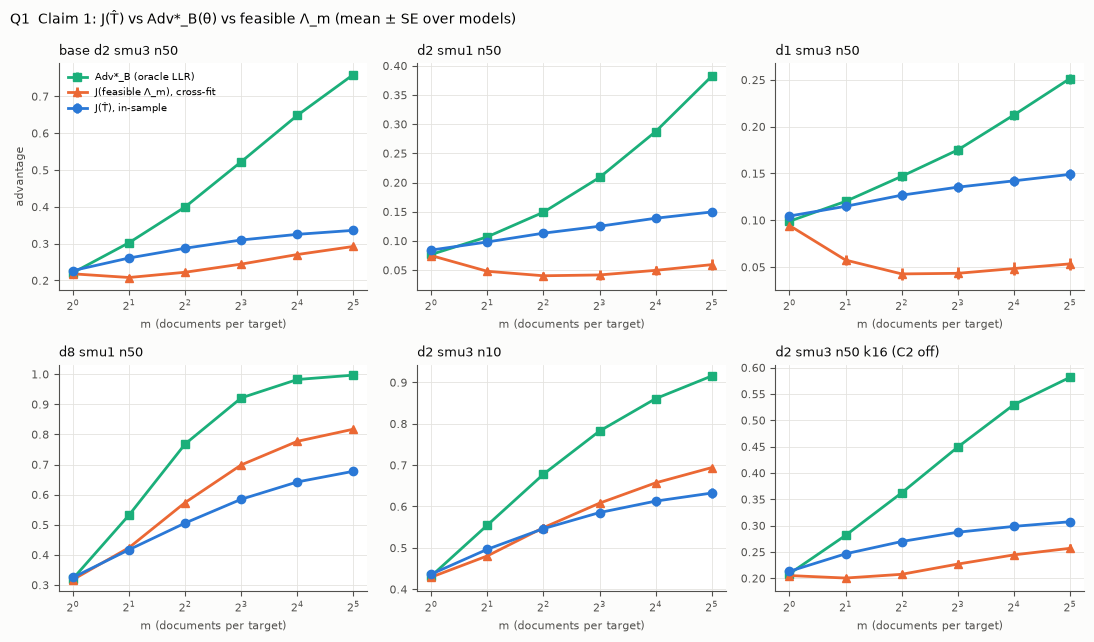

m,1,2,4,8,16,32
J_cf(feasible Λ_m),,,,,,
base d2 smu3 n50,0.218,0.208,0.222,0.245,0.271,0.292
d1 smu3 n50,0.094,0.057,0.043,0.043,0.048,0.053
d2 smu1 n50,0.075,0.048,0.040,0.042,0.050,0.059
d2 smu3 n10,0.429,0.481,0.549,0.608,0.657,0.694
d2 smu3 n50 k16 (C2 off),0.205,0.200,0.208,0.227,0.244,0.257
d8 smu1 n50,0.318,0.424,0.574,0.699,0.777,0.817


m,1,2,4,8,16,32
J_cf(T̂),,,,,,
base d2 smu3 n50,0.219,0.255,0.281,0.304,0.319,0.330
d1 smu3 n50,0.093,0.104,0.119,0.127,0.135,0.143
d2 smu1 n50,0.076,0.087,0.101,0.116,0.130,0.142
d2 smu3 n10,0.430,0.490,0.542,0.580,0.609,0.629
d2 smu3 n50 k16 (C2 off),0.205,0.239,0.262,0.280,0.291,0.300
d8 smu1 n50,0.318,0.412,0.500,0.580,0.637,0.673


In [4]:
S.fig_q1(r1); plt.show()
display(q1.pivot(index="config", columns="m", values="J_cf_feas").round(3).rename_axis("J_cf(feasible Λ_m)"))
display(q1.pivot(index="config", columns="m", values="J_cf_that").round(3).rename_axis("J_cf(T̂)"))

**Read before moving on**
- Is the m = 1 gap ≈ 0? It should be slightly negative: that is the upward bias of `J_in`.
- Does the gap grow with m in every Assumption-2 configuration?
- Does the feasible Λ_m beat T̂ anywhere? If not, the product reference is the problem. That bears on S_cat, which replaces the product with one joint context in **both** p_θ and p_ref.

## 2. Proposition 6: variance decomposition, eq. (3), ceiling

Per model: τ_u and Var(s | u) by Gauss–Hermite (members: all n users exactly; non-members: fresh users).
- `var_ratio` = measured Var(S_m | b) / (v_B + v_W/m). This identity is exact, so the ratio should be ≈ 1 up to Monte-Carlo error.
- `auc_pred` (eq. 3, Gaussian approximation) vs `auc_meas`; `ceil_exact` = AUROC(τ) vs `ceil_pred`.

**Step-F pilot:** what Stage 2 will do on Enron. That is n₁ = n₀ ∈ {34, 68} users and 32 held-out docs per user, followed by the plug-in v̂_B, v̂_W, Δ̂ and the prediction. This shows whether a prediction-vs-measurement gap is even detectable at that scale.

  [q2] base d2 smu3 n50: 65s
  [q2] d2 smu1 n50: 63s
  [q2] d2 smu3 n50 k16 (C2 off): 65s
  [q2] Step-F pilot done
[stage0_q2] computed in 227s -> c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results\stage0_q2.json


,config,m,auc_meas,auc_meas_se,auc_pred,var_ratio_b1,var_ratio_b0,ceil_exact,ceil_pred,pred_minus_meas
0,base d2 smu3 n50,1,0.650,0.004,0.633,1.000,1.078,0.716,0.661,-0.017
1,base d2 smu3 n50,2,0.672,0.005,0.645,1.003,1.074,0.716,0.661,-0.028
2,base d2 smu3 n50,4,0.690,0.005,0.652,1.001,1.068,0.716,0.661,-0.038
3,base d2 smu3 n50,8,0.701,0.005,0.656,1.001,1.062,0.716,0.661,-0.044
4,base d2 smu3 n50,16,0.707,0.005,0.659,1.004,1.058,0.716,0.661,-0.049
5,base d2 smu3 n50,32,0.711,0.005,0.660,1.005,1.056,0.716,0.661,-0.052
6,d2 smu1 n50,1,0.553,0.004,0.558,1.007,0.994,0.598,0.609,0.004
7,d2 smu1 n50,2,0.565,0.004,0.572,1.002,0.996,0.598,0.609,0.007
8,d2 smu1 n50,4,0.576,0.005,0.585,1.006,0.993,0.598,0.609,0.009
9,d2 smu1 n50,8,0.584,0.005,0.594,0.996,0.991,0.598,0.609,0.011


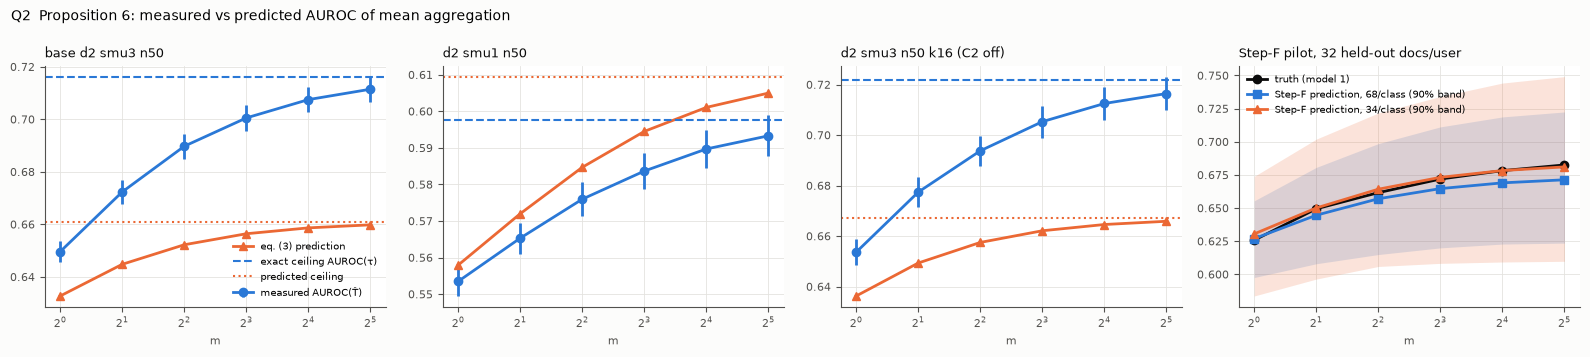

In [5]:
r2 = cached("stage0_q2", lambda: S.run_q2(**BUD["q2"]))
rows = []
for c in r2["configs"]:
    for j, m in enumerate(r2["m_grid"]):
        rows.append(dict(config=c["label"], m=m, auc_meas=c["auc_meas"][j], auc_meas_se=c["auc_meas_se"][j],
                         auc_pred=c["auc_pred"][j], var_ratio_b1=c["var_ratio1"][j], var_ratio_b0=c["var_ratio0"][j],
                         ceil_exact=c["ceil_exact"][0], ceil_pred=c["ceil_pred"][0]))
q2 = pd.DataFrame(rows)
q2["pred_minus_meas"] = q2.auc_pred - q2.auc_meas
display(q2.round(3))
S.fig_q2(r2); plt.show()

In [6]:
rows = []
for i, mod in enumerate(r2["pilot"]["models"]):
    for n_cls, e in mod["est"].items():
        rows.append(dict(model=i, users_per_class=int(n_cls),
                         true_ceiling=mod["truth"]["ceil_exact"],
                         pred_ceiling=e["pred_ceil"]["mean"], pred_ceiling_q05=e["pred_ceil"]["q05"], pred_ceiling_q95=e["pred_ceil"]["q95"],
                         true_auc_m32=mod["truth"]["auc_meas"][-1],
                         meas_auc_m32=e["meas_auc"]["mean"][-1], meas_q05=e["meas_auc"]["q05"][-1], meas_q95=e["meas_auc"]["q95"][-1]))
display(pd.DataFrame(rows).round(3))

,model,users_per_class,true_ceiling,pred_ceiling,pred_ceiling_q05,pred_ceiling_q95,true_auc_m32,meas_auc_m32,meas_q05,meas_q95
0,0,34,0.696,0.684,0.610,0.753,0.682,0.694,0.608,0.786
1,0,68,0.696,0.674,0.624,0.726,0.682,0.691,0.639,0.743
2,1,34,0.735,0.718,0.637,0.804,0.726,0.735,0.643,0.825
3,1,68,0.735,0.710,0.646,0.771,0.726,0.733,0.678,0.788
4,2,34,0.711,0.669,0.610,0.738,0.698,0.695,0.603,0.792
5,2,68,0.711,0.656,0.608,0.705,0.698,0.694,0.635,0.754
6,3,34,0.708,0.688,0.619,0.754,0.699,0.702,0.613,0.787
7,3,68,0.708,0.685,0.638,0.734,0.699,0.705,0.653,0.757


**Read before moving on**
- `var_ratio` ≈ 1 for both classes? A deviation for non-members can come from heavy tails of s(x) for far-away users. Check the SE before calling it a failure.
- How far is eq. (3) from the measurement, and is the error systematic (the Gaussian approximation) or noise?
- Pilot: is the 90 % band of the predicted ceiling narrower than the effect we want to detect in Stage 2?

## 3. Corollary 2: light users

Heterogeneous contributions k_u ∈ [2, 512] (log-uniform), α_u = k_u / Σk, and exact components, so (C2) and (C3) hold.
Per member: τ_u = own + typicality (exact identity), and the sandwich α_u KL(D_u‖D_{−u}) ≤ own ≤ log(1 + α_u χ²(D_u‖D_{−u})).
Per-user TPR at FPR γ = 5 % for T̂ and for the oracle LLR, at m ∈ {1, 4, 16, 64, 256}.

Note: these targets are drawn **uniformly** over members, whereas the draft's (C1) uses α-weighted targets. Per-user TPR does not depend on this choice.

  [q3] base d2 smu3: 65s
  [q3] overlap d2 smu1: 61s
[stage0_q3] computed in 126s -> c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results\stage0_q3.json


**base d2 smu3**: 400 member users; identity error 1.8e-15; sandwich violations lower 0, upper 0; users with τ_u > t_γ: 55; users meeting the 'never detected' condition: 328

,m=1,m=4,m=16,m=64,m=256
TPR T̂ / oracle,,,,,
"k∈[2,7] (n=85, limit 0.04)",0.05 / 0.16,0.05 / 0.26,0.04 / 0.43,0.04 / 0.77,0.03 / 0.99
"k∈[8,31] (n=126, limit 0.03)",0.04 / 0.11,0.05 / 0.20,0.04 / 0.40,0.04 / 0.77,0.03 / 0.99
"k∈[32,127] (n=87, limit 0.15)",0.10 / 0.14,0.12 / 0.24,0.13 / 0.42,0.14 / 0.78,0.15 / 0.99
"k∈[128,512] (n=102, limit 0.34)",0.23 / 0.15,0.29 / 0.25,0.32 / 0.45,0.33 / 0.79,0.33 / 0.99


,1,4,16,64,256
mean |TPR_u(m) − 1{τ_u>t_γ}|,0.091,0.067,0.040,0.022,0.012
max TPR(T̂) among 'never detected' users,0.405,0.370,0.435,0.400,0.290


**overlap d2 smu1**: 400 member users; identity error 2.2e-16; sandwich violations lower 0, upper 0; users with τ_u > t_γ: 38; users meeting the 'never detected' condition: 356

,m=1,m=4,m=16,m=64,m=256
TPR T̂ / oracle,,,,,
"k∈[2,7] (n=96, limit 0.05)",0.05 / 0.07,0.05 / 0.11,0.05 / 0.17,0.06 / 0.27,0.05 / 0.50
"k∈[8,31] (n=99, limit 0.10)",0.05 / 0.07,0.07 / 0.10,0.08 / 0.15,0.09 / 0.29,0.10 / 0.54
"k∈[32,127] (n=108, limit 0.06)",0.06 / 0.08,0.07 / 0.14,0.07 / 0.21,0.08 / 0.35,0.07 / 0.58
"k∈[128,512] (n=97, limit 0.16)",0.10 / 0.09,0.14 / 0.13,0.16 / 0.18,0.18 / 0.31,0.18 / 0.55


,1,4,16,64,256
mean |TPR_u(m) − 1{τ_u>t_γ}|,0.099,0.070,0.042,0.023,0.012
max TPR(T̂) among 'never detected' users,0.255,0.345,0.410,0.440,0.405


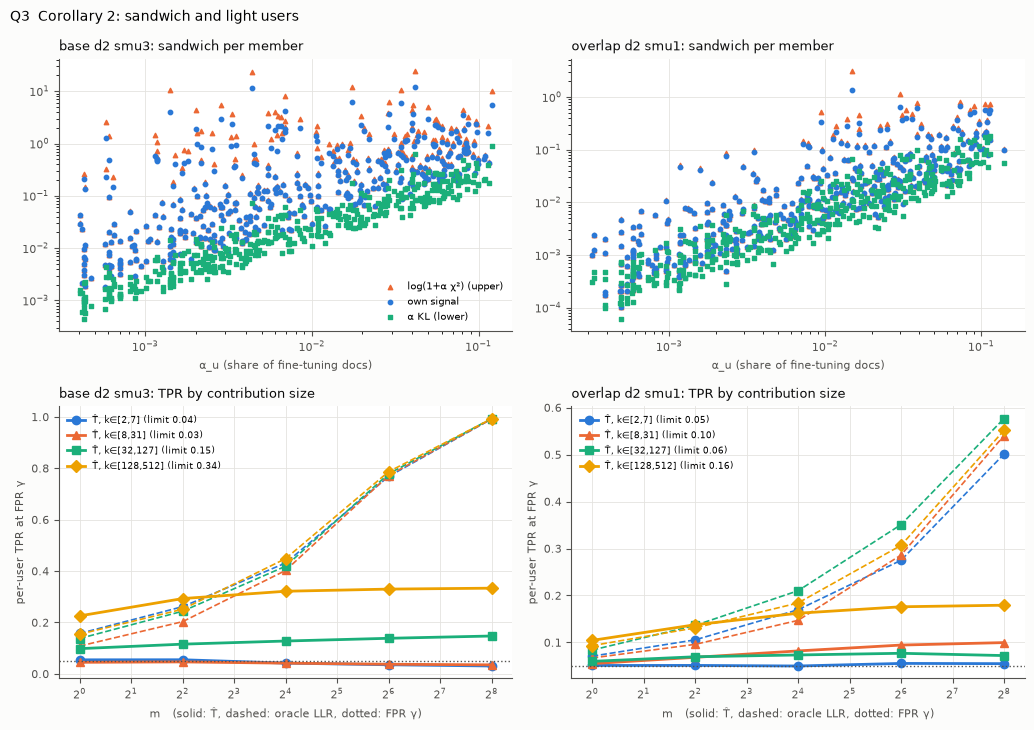

In [7]:
r3 = cached("stage0_q3", lambda: S.run_q3(**BUD["q3"]))
for c in r3["configs"]:
    display(Markdown(f"**{c['label']}**: {c['n_users']} member users; identity error {c['identity_max_abs']:.1e}; "
                     f"sandwich violations lower {c['sandwich_lower_violations']}, upper {c['sandwich_upper_violations']}; "
                     f"users with τ_u > t_γ: {c['limit_count']}; users meeting the 'never detected' condition: {c['never_count']}"))
    edges = r3["k_edges"]
    t = pd.DataFrame({f"k∈[{edges[b]},{edges[b+1]-1}] (n={c['bin_count'][b]}, limit {c['bin_limit_frac'][b]:.2f})":
                      [f"{a:.2f} / {o:.2f}" for a, o in zip(c["bin_tpr_that"][b], c["bin_tpr_oracle"][b])]
                      for b in range(len(edges) - 1)}, index=[f"m={m}" for m in r3["m_grid"]])
    display(t.T.rename_axis("TPR  T̂ / oracle"))
    dev = pd.Series(c["abs_dev_from_limit"], index=r3["m_grid"], name="mean |TPR_u(m) − 1{τ_u>t_γ}|")
    never = pd.Series(c["never_users_tpr_that_max"] or [np.nan] * len(r3["m_grid"]), index=r3["m_grid"],
                      name="max TPR(T̂) among 'never detected' users")
    display(pd.concat([dev, never], axis=1).T.round(3))
S.fig_q3(r3); plt.show()

**Read before moving on**
- Sandwich violations should be 0. The bounds hold for any α and any D_u, D_{−u}: concavity of the log for the lower bound, Jensen's inequality for the upper.
- `mean |TPR_u(m) − 1{τ_u>t_γ}|` should shrink with m (the limit statement).
- "Never detected" users: is the maximum TPR > 0 at finite m? If so, the draft's "for any m" must become "as m → ∞".
- Does the oracle detect light users that T̂ cannot? That is the contrast Cor. 2 is meant to support.

## 4. Context from `ui_toy` (the note's experiments)
E1: m sweep in the base configuration (plateau and variance components). E2c: TPR by contribution size at m = 8.
E6: DKW certificate coverage and its false-positive rate under the null, vs users per class (Prop. 2(ii), Cor. 1).
E2a (crowd size, ~17 min), E2b, E3b and E5 are also cached if present. Run `python ui_toy.py E2a E2b E3b E5` to (re)make them.

In [8]:
W = T.World(2, 1.0, 3.0)
e1 = cached("E1", lambda: T.exp_m_sweep(W, B=4 if QUICK else 40, R=1000 if QUICK else 5000))
print("Prop. 5(a): max |T̂ − Λ₁| at m=1 =", e1["max_abs_gap_kandpal_vs_opt_m1"])
display(pd.DataFrame({"AUROC T̂": e1["kandpal_auroc_mean"], "AUROC oracle": e1["opt_auroc_mean"],
                      "Adv* (Λ>0)": e1["adv0_mean"], "J T̂ (model-calibrated)": e1["kandpal_roc_adv"]},
                     index=pd.Index(e1["m_grid"], name="m")).round(3))
print("T̂ plateau AUROC(τ):", round(e1["kandpal_plateau_mean"], 3), "| variance components:",
      {k: round(v, 3) for k, v in e1["kandpal_varcomp"].items()})

[E1] loaded from c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results\E1.json
Prop. 5(a): max |T̂ − Λ₁| at m=1 = 0.0


,AUROC T̂,AUROC oracle,Adv* (Λ>0),J T̂ (model-calibrated)
m,,,,
1,0.655,0.655,0.214,0.213
2,0.678,0.709,0.292,0.244
4,0.697,0.772,0.394,0.273
8,0.710,0.838,0.517,0.292
16,0.718,0.896,0.645,0.304
32,0.722,0.939,0.757,0.310
64,0.724,0.967,0.844,0.313
128,0.726,0.983,0.904,0.314
256,0.726,0.991,0.944,0.316


T̂ plateau AUROC(τ): 0.726 | variance components: {'tau_in': 0.194, 'tau_out': -0.32, 'vB_in': 0.185, 'vB_out': 1.228, 'vW_in': 0.178, 'vW_out': 0.594}


In [9]:
e6 = cached("E6", lambda: T.exp_estimation(W, big=100_000 if QUICK else 1_000_000, reps=40 if QUICK else 400))
display(pd.DataFrame({"users/class": e6["sizes"],
                      "coverage (cert ≤ true J), leak": e6["leak_dkw_coverage"],
                      "P(cert > 0), leak": e6["leak_dkw_positive"],
                      "P(cert > 0), null": e6["null_dkw_positive"]}).set_index("users/class").round(3))
print("true J (m=8):", round(e6["truth"]["ks"], 3), "| required users/class by Cor. 1:",
      int(cert.users_needed(e6["truth"]["ks"])) + 1)

[E6] loaded from c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results\E6.json


,"coverage (cert ≤ true J), leak","P(cert > 0), leak","P(cert > 0), null"
users/class,,,
25,1.0,0.025,0.0
50,1.0,0.240,0.0
100,1.0,0.708,0.0
200,1.0,0.998,0.0
500,1.0,1.000,0.0
1000,1.0,1.000,0.0
2000,1.0,1.000,0.0
5000,1.0,1.000,0.0


true J (m=8): 0.282 | required users/class by Cor. 1: 111


In [10]:
e2c = cached("E2c", lambda: T.exp_hetero(W, B=6 if QUICK else 80, R=1000 if QUICK else 5000))
display(pd.DataFrame({"count": e2c["count"], "TPR T̂ (noisy)": e2c["tpr_kandpal_noisy"], "TPR oracle (noisy)": e2c["tpr_opt_noisy"],
                      "TPR T̂ (exact)": e2c["tpr_kandpal_exact"], "TPR oracle (exact)": e2c["tpr_opt_exact"]},
                     index=pd.Index([f"[{a:g},{b:g})" for a, b in zip(e2c["k_edges"][:-1], e2c["k_edges"][1:])], name="k bin")).round(3))

[E2c] loaded from c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\results\E2c.json


,count,TPR T̂ (noisy),TPR oracle (noisy),TPR T̂ (exact),TPR oracle (exact)
k bin,,,,,
"[2,4)",47923.0,0.064,0.145,0.065,0.340
"[4,8)",52134.0,0.052,0.176,0.052,0.326
"[8,16)",47734.0,0.053,0.226,0.053,0.302
"[16,32)",50598.0,0.058,0.281,0.060,0.313
"[32,64)",49929.0,0.105,0.324,0.105,0.319
"[64,128)",52776.0,0.135,0.344,0.136,0.323
"[128,256)",49637.0,0.248,0.361,0.249,0.329
"[256,512)",49269.0,0.376,0.350,0.378,0.320


## 5. Gate verdict
Automatic part only. The interpretation goes in the notes cell below, written after reading the blocks above.

In [11]:
a2 = q1.groupby("config").A2.first()
holds = verdict1[a2[a2].index]
print("Claim 1 (Assumption-2 configs):", "HOLDS in all" if holds.all() else f"FAILS in {list(holds[~holds].index)}")
print("Claim 1 (C2 off, k=16):", "holds" if verdict1[a2[~a2].index].all() else "fails")
print("Prop. 6 max |var ratio − 1|:", round(float(np.abs(q2[["var_ratio_b1", "var_ratio_b0"]] - 1).max().max()), 3),
      "| max |eq.3 − measured|:", round(float(q2.pred_minus_meas.abs().max()), 3))
print("Cor. 2 sandwich violations:", sum(c["sandwich_lower_violations"] + c["sandwich_upper_violations"] for c in r3["configs"]))
S.make_figs(); S.make_summary() if not QUICK else None;

Claim 1 (Assumption-2 configs): HOLDS in all
Claim 1 (C2 off, k=16): holds
Prop. 6 max |var ratio − 1|: 0.078 | max |eq.3 − measured|: 0.052
Cor. 2 sandwich violations: 0
  figures -> c:\Users\JALAL\OneDrive\Documents\MIA_UIA\Stage0\figs
# Stage 0 summary (auto-generated by stage0_checks.py)

## Q1 Claim 1: Adv*_B(θ) − J_in(T̂)  (J_in is biased up, so this gap is conservative)

| config | A2 | m=1 | m=2 | m=4 | m=8 | m=16 | m=32 | holds for all m≥2 |
|---|---|---|---|---|---|---|---|---|
| base d2 smu3 n50 | yes | -0.006±0.001 | +0.042±0.002 | +0.112±0.003 | +0.213±0.005 | +0.323±0.006 | +0.423±0.007 | YES |
| d2 smu1 n50 | yes | -0.008±0.001 | +0.009±0.002 | +0.036±0.002 | +0.084±0.004 | +0.148±0.006 | +0.232±0.007 | YES |
| d1 smu3 n50 | yes | -0.006±0.001 | +0.005±0.001 | +0.020±0.003 | +0.040±0.003 | +0.070±0.005 | +0.102±0.005 | YES |
| d8 smu1 n50 | yes | -0.004±0.000 | +0.115±0.002 | +0.263±0.002 | +0.337±0.003 | +0.340±0.003 | +0.319±0.004 | YES |
| d2 smu3 n10 | yes | -0.005±0

## Notes (written 2026-11-23, after the full-budget run)

Everything below holds in the hierarchical Gaussian toy model only. It says nothing yet about an LLM.

**Claim 1: holds numerically.**
- With m = 1 document per user, T̂ is optimal: the gap Adv\*_B − J_in(T̂) is −0.004 to −0.008. That negative value is the upward bias of the in-sample J.
- For every m ≥ 2, the gap is positive by more than 2 SE in all 6 configurations, including C2 off (k = 16). It grows with m. At m = 32 it ranges from +0.10 (d = 1) to +0.42 (base).
- For the paper: mean aggregation (Kandpal) understates user-level leakage.
- Numerical evidence is not a proof. The plan still lists Claim 1 as TODO.

**Feasible Λ_m (product of per-document references): not reliably better than T̂.**
- At m = 32, its cross-fitted J is below T̂'s in 4 of 6 configurations, and above it only when the signal is strong (d8 smu1, n10).
- The gain promised by Claim 1 depends on a good reference or population model. This is a risk for S_cat in Stage 2.
- The definition is my reading of the draft and still needs confirming.

**Prop. 6 / eq. (3).**
- The decomposition Var(S_m | b) = v_B + v_W/m is confirmed: |ratio − 1| ≤ 0.01 for b = 1 and ≤ 0.08 for b = 0.
- Eq. (3) predicts the measured AUROC to within 0.05.
- Its ceiling is about 0.055 too low when users are well separated (0.661 vs the exact 0.716). It is a guide, not a precise predictor.
- AUROC saturates with m. For T̂ the ceiling is around 0.7 in these configurations.

**Step-F pilot, implications for Stage 2.**
- With 68 members and 32 held-out docs, the 95% band on the predicted ceiling is about ±0.05. With 34 per class it is about ±0.07.
- AUROC differences below about 0.05 between statistics are not resolvable at Enron scale.

**Certificates (E6, true J ≈ 0.28, m = 8).**
- The DKW certificate never fired on null data, and it covered the truth every time.
- It was positive in 2.5% of trials with 25 users, 24% with 50, 71% with 100 and about 100% with 200.
- With 68 users (or 34 after FIT/EVAL), a positive certificate is not guaranteed even when leakage is real. This is the main practical constraint.

**Cor. 2.**
- The identity τ = own + typicality holds exactly. The sandwich had 0 violations over 800 member users.
- Per-user TPR converges to 1{τ_u > t_γ}: the mean error goes from 0.09 at m = 1 to 0.012 at m = 256.
- The draft's "never detected, for any m" is false at finite m. Those users have a mean TPR of about 0.006, but the maximum is 0.29–0.44 even at m = 256. Change the wording to "TPR_u(m) → 0 as m → ∞", as the plan already says.
- T̂ misses light users while the oracle does not. In the separated configuration, T̂'s TPR is 0.03 for k ≤ 7 and 0.33 for k ≥ 128; the oracle's is about 0.99 in every k bin. In the overlap configuration the oracle reaches 0.50–0.58 in every k bin.
- Caveat: `ui_toy` draws targets uniformly, while draft C1 weights them by α.

**Fixes to carry over.**
- Plan Cor. 1 table: 219 → 220 and 876 → 877.
- Draft Cor. 2 wording (see above).
- Hold out a fixed 32 docs per user instead of 10%.

**Gate decision: PASSED.** Claim 1 holds numerically, so the C3 story stands. Stage 0 is closed. Next: data (Enron), then Stage 1 (reproduce Kandpal).